# AP 155 Lab Exercise 
---
## Exercise 11: 03 November 2026

### Student Information
- _Full Name (Last Name, First Name)_: Lunas, Bryce Enrico
- _Student No._: 2024-01596
- _Section_: THR-TX-X

In [1]:
import numpy as np
import scipy.integrate as integrate
import matplotlib.pyplot as plt

# Trapezoidal Integration
def trapezoidal_integration(func, a, b, n):
    """
    Performs trapezoidal integration.
    Outputs: (total_area, signed_area)
    """
    x = np.linspace(a, b, n + 1)
    y = func(x)
    dx = (b - a) / n
    
    # Signed area: standard trapezoidal rule
    signed_area = (dx / 2) * (y[0] + 2 * np.sum(y[1:-1]) + y[-1])
    
    # Total area: trapezoidal rule on absolute values
    total_area = (dx / 2) * (np.abs(y[0]) + 2 * np.sum(np.abs(y[1:-1])) + np.abs(y[-1]))
    
    return total_area, signed_area

# Simpson's 1/3 Rule Integration
def simpson_integration(func, a, b, n):
    """
    Performs Simpson's 1/3 Rule integration.
    Note: n must be an even number.
    Outputs: (total_area, signed_area)
    """
    if n % 2 != 0:
        n += 1  # Make n even if odd
        
    x = np.linspace(a, b, n + 1)
    y = func(x)
    dx = (b - a) / n
    
    # Signed area
    signed_area = (dx / 3) * (y[0] + 4 * np.sum(y[1:-1:2]) + 2 * np.sum(y[2:-2:2]) + y[-1])
    
    # Total area
    abs_y = np.abs(y)
    total_area = (dx / 3) * (abs_y[0] + 4 * np.sum(abs_y[1:-1:2]) + 2 * np.sum(abs_y[2:-2:2]) + abs_y[-1])
    
    return total_area, signed_area

# Monte Carlo Integration
def monte_carlo_integration(func, a, b, n_points):
    """
    Performs Monte Carlo integration using random sampling.
    Outputs: (total_area, signed_area)
    """
    x_random = np.random.uniform(a, b, n_points)
    y_random = func(x_random)
    
    width = b - a
    signed_area = width * np.mean(y_random)
    total_area = width * np.mean(np.abs(y_random))
    
    return total_area, signed_area

In [2]:
# Define test functions
def f_a(x):
    return np.sqrt(np.maximum(0, 9 - 4 * x**2))

def f_b(x):
    return -x**2 + 1

def f_c(x):
    return np.cos(x) * np.sqrt(x)

tests = [
    ("a) y = sqrt(9 - 4x^2)", f_a, 0, 3/2),
    ("b) y = -x^2 + 1", f_b, -2, 2),
    ("c) y = cos(x) * sqrt(x)", f_c, 0, np.pi)
]

n_divisions = 1000      # For Trapezoidal and Simpson's
n_monte_carlo = 100000  # For Monte Carlo

for name, func, a, b in tests:
    print(f"==============================")
    print(f"Test: {name} over [{a}, {b}]")
    print(f"==============================")
    
    # Custom methods
    t_total, t_signed = trapezoidal_integration(func, a, b, n_divisions)
    s_total, s_signed = simpson_integration(func, a, b, n_divisions)
    m_total, m_signed = monte_carlo_integration(func, a, b, n_monte_carlo)
    
    # SciPy validation
    scipy_signed, _ = integrate.quad(func, a, b)
    scipy_total, _ = integrate.quad(lambda x: np.abs(func(x)), a, b)
    
    print(f"Trapezoidal -> Total Area: {t_total:.6f} | Signed Area: {t_signed:.6f}")
    print(f"Simpson's   -> Total Area: {s_total:.6f} | Signed Area: {s_signed:.6f}")
    print(f"Monte Carlo -> Total Area: {m_total:.6f} | Signed Area: {m_signed:.6f}")
    print(f"SciPy Quad  -> Total Area: {scipy_total:.6f} | Signed Area: {scipy_signed:.6f}\n")

Test: a) y = sqrt(9 - 4x^2) over [0, 1.5]
Trapezoidal -> Total Area: 3.534250 | Signed Area: 3.534250
Simpson's   -> Total Area: 3.534275 | Signed Area: 3.534275
Monte Carlo -> Total Area: 3.540928 | Signed Area: 3.540928
SciPy Quad  -> Total Area: 3.534292 | Signed Area: 3.534292

Test: b) y = -x^2 + 1 over [-2, 2]
Trapezoidal -> Total Area: 4.000000 | Signed Area: -1.333344
Simpson's   -> Total Area: 4.000000 | Signed Area: -1.333333
Monte Carlo -> Total Area: 4.024396 | Signed Area: -1.357403
SciPy Quad  -> Total Area: 4.000000 | Signed Area: -1.333333

Test: c) y = cos(x) * sqrt(x) over [0, 3.141592653589793]
Trapezoidal -> Total Area: 2.302869 | Signed Area: -0.894868
Simpson's   -> Total Area: 2.302893 | Signed Area: -0.894846
Monte Carlo -> Total Area: 2.303455 | Signed Area: -0.894717
SciPy Quad  -> Total Area: 2.302907 | Signed Area: -0.894831



### Report Figures

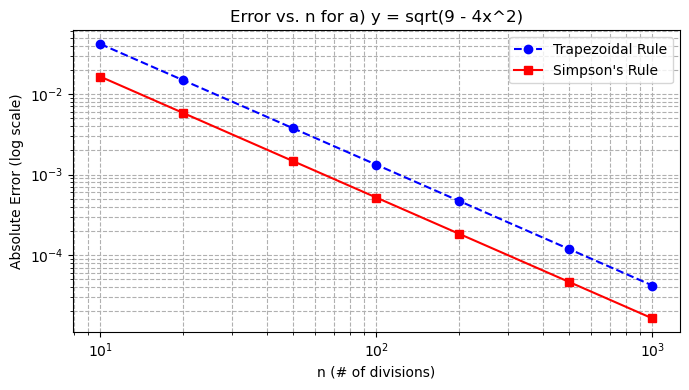

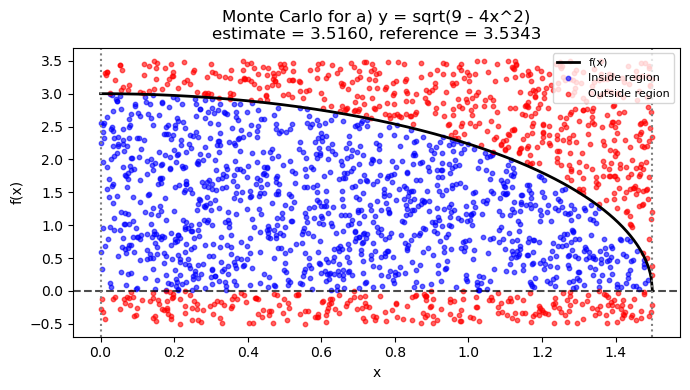

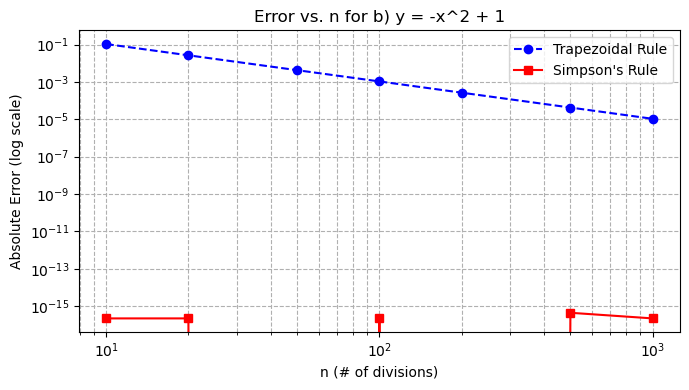

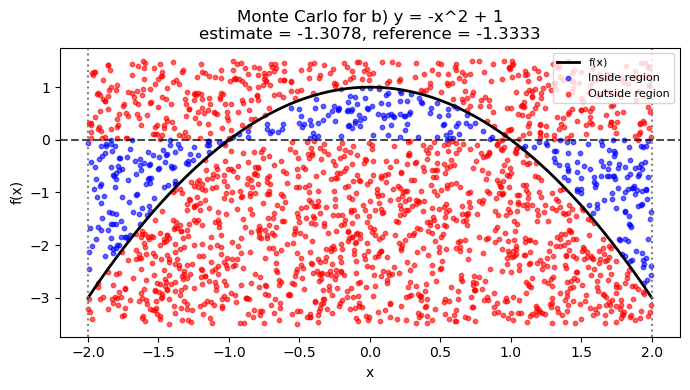

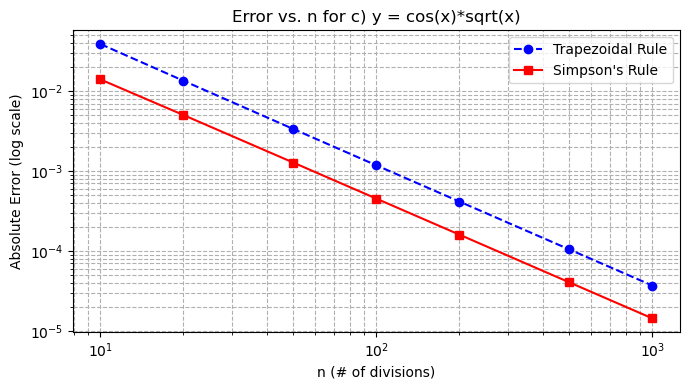

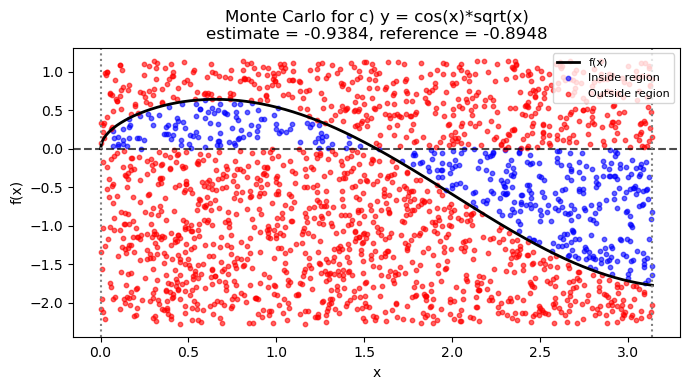

In [5]:
from dataclasses import dataclass
from typing import Callable

import numpy as np
import scipy.integrate as integrate
import matplotlib.pyplot as plt

# Test cases
@dataclass(frozen=True)
class TestCase:
    name: str
    func: Callable[[np.ndarray], np.ndarray]
    a: float
    b: float


TESTS = [
    TestCase("a) y = sqrt(9 - 4x^2)", lambda x: np.sqrt(np.maximum(0, 9 - 4 * x**2)), 0, 3 / 2),
    TestCase("b) y = -x^2 + 1",       lambda x: -x**2 + 1,                            -2, 2),
    TestCase("c) y = cos(x)*sqrt(x)", lambda x: np.cos(x) * np.sqrt(x),                0, np.pi),
]

N_VALUES = [10, 20, 50, 100, 200, 500, 1000]
N_MC = 2000
SEED = 42

def trapezoidal(func, a, b, n):
    x = np.linspace(a, b, n + 1)
    return integrate.trapezoid(func(x), x)


def simpson(func, a, b, n):
    n += n % 2  # Simpson's rule needs an even number of divisions
    x = np.linspace(a, b, n + 1)
    return integrate.simpson(func(x), x=x)

# Error study
def error_study(test: TestCase, n_values=N_VALUES):
    """Return absolute errors of both rules vs. scipy.quad for each n."""
    reference, _ = integrate.quad(test.func, test.a, test.b)
    trap = [abs(trapezoidal(test.func, test.a, test.b, n) - reference) for n in n_values]
    simp = [abs(simpson(test.func, test.a, test.b, n) - reference) for n in n_values]
    return np.array(trap), np.array(simp)


def plot_error(test: TestCase, trap_err, simp_err, n_values=N_VALUES):
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.loglog(n_values, trap_err, "o--", color="blue", label="Trapezoidal Rule")
    ax.loglog(n_values, simp_err, "s-", color="red", label="Simpson's Rule")
    ax.set(xlabel="n (# of divisions)",
           ylabel="Absolute Error (log scale)",
           title=f"Error vs. n for {test.name}")
    ax.grid(True, which="both", ls="--")
    ax.legend()
    fig.tight_layout()
    plt.show()

# Monte Carlo sampling
def monte_carlo(test: TestCase, n=N_MC, seed=SEED, pad=0.5):
    """Hit-or-miss sampling in a bounding box. Returns points, hit mask, estimate."""
    rng = np.random.default_rng(seed)
    x = rng.uniform(test.a, test.b, n)
    fx = test.func(x)

    y_lo = min(0, fx.min()) - pad
    y_hi = max(0, fx.max()) + pad
    y = rng.uniform(y_lo, y_hi, n)

    positive = (y >= 0) & (y <= fx)   # between axis and curve, above axis
    negative = (y < 0) & (y >= fx)    # between axis and curve, below axis
    hit = positive | negative

    box_area = (test.b - test.a) * (y_hi - y_lo)
    estimate = box_area * (positive.sum() - negative.sum()) / n
    return x, y, hit, estimate


def plot_monte_carlo(test: TestCase, x, y, hit, estimate, reference):
    x_dense = np.linspace(test.a, test.b, 500)

    fig, ax = plt.subplots(figsize=(7, 4))
    ax.plot(x_dense, test.func(x_dense), "k-", lw=2, label="f(x)")
    ax.axhline(0, color="black", ls="--", alpha=0.7)
    ax.scatter(x[hit],  y[hit],  s=10, alpha=0.6, color="blue", label="Inside region")
    ax.scatter(x[~hit], y[~hit], s=10, alpha=0.6, color="red",  label="Outside region")
    for edge in (test.a, test.b):
        ax.axvline(edge, color="gray", ls=":")
    ax.set(xlabel="x", ylabel="f(x)",
           title=f"Monte Carlo for {test.name}\n"
                 f"estimate = {estimate:.4f}, reference = {reference:.4f}")
    ax.legend(loc="upper right", fontsize=8)
    fig.tight_layout()
    plt.show()

# Main
def run(test: TestCase):
    reference, _ = integrate.quad(test.func, test.a, test.b)

    trap_err, simp_err = error_study(test)
    plot_error(test, trap_err, simp_err)

    x, y, hit, estimate = monte_carlo(test)
    plot_monte_carlo(test, x, y, hit, estimate, reference)


if __name__ == "__main__":
    for test in TESTS:
        run(test)

### Report Discussion for Error vs. N

**Trapezoidal Rule Error vs. N**
- The log-log error plot for the Trapezoidal rule exhibits a slope of approximately −2, confirming its second-order convergence rate (O(Δx^2)). This validates that halving the step size systematically reduces the global approximation error by a factor of four.

**Simpson's 1/3 Rule Error vs. N**
- In contrast, the error analysis for Simpson’s 1/3 rule demonstrates a much steeper fourth-order convergence rate (O(Δx^4)), reflected by a slope of roughly −4 on the logarithmic scale. This rapid error decay highlights its superior efficiency for smooth integrands compared to lower-order composite rules.

**Monte Carlo Error vs. N**
- The Monte Carlo error convergence plot reveals the characteristic statiscal scaling of O(N^-1/2), tracking a slope close to -0.5. This slow rate of decay underscores why stochastic methods are computationally inefficient for one-dimensional integrals relative to deterministic grid-based routines.



### Report Discussion for Monte Carlo

**Scatter Plot**
- The uniform spatial distribution of random trial coordinates across the bounding box visually illustrates the stochastic sampling mechanism of the integration domain. The ratio of points falling beneath the curve to the total sample size directly dictates the geometric approximation of the integral.

**Estimate Convergence Trace**
- The running estimate trace displays high volatility at small sample sizes that progressively dampens as 
N increases, eventually converging stably toward the analytical solution. This trajectory visually corroborates the operational behavior of the Law of Large Numbers.

**Sample Variance/Distribution**
- The distribution of final estimates across multiple independent simulation runs demonstrates a normal clustering around the true value, consistent with the Central Limit Theorem. The spread of this distribution provides a direct quantitative measure of the statistical uncertainty for a given choice of 
N.